In [1]:
import sys
import numpy as np
import pandas as pd
from pathlib import Path
sys.path.insert(0, "kev")
from models.kev_pointer import KevEncoder

import math
import random
import torch
from models.kev_pointer import KevPointerModel
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

import shutil

from IPython.display import display

data_dir = Path.cwd()/'data/issp2022'
long = pd.read_parquet(data_dir/'issp2022_US_long.parquet')
for c in ("option_codes", "option_texts"):
    long[c] = long[c].map(list)                                        # parquet gives arrays; the draws expect lists
persona = list(long.columns[1:long.columns.get_loc("v")])              # the columns between CASEID and v
country = long["c_alphan"].iloc[0]
long.head(2)

,CASEID,c_alphan,SEX,AGE,EDULEVEL,RELIGGRP,ATTEND,PARTY_LR,VOTE_LE,URBRURAL,...,US_ETHN1,v,label,question,type,reversed,option_codes,option_texts,answer_code,answer_text
0,2022008400000002,US,Male,80,"Upper level tertiary, MA",Catholic,Once or twice a year,Center / liberal,Yes,The suburbs or outskirts of a big city,...,Austria,v1,Q1a Working mom can establish as warm relation...,"To begin, we have some questions about women. ...",score,True,"[1, 2, 3, 4, 5]","[Strongly agree, Agree, Neither agree nor disa...",3,Neither agree nor disagree
1,2022008400000004,US,Female,23,"Lower level tertiary, BA",No religion,Once a month,NaN,NaN,The suburbs or outskirts of a big city,...,England and Wales,v1,Q1a Working mom can establish as warm relation...,"To begin, we have some questions about women. ...",score,True,"[1, 2, 3, 4, 5]","[Strongly agree, Agree, Neither agree nor disa...",2,Agree


In [2]:
encoder = KevEncoder.for_base("jaredpalmer/kev-0.8b")

view = {"state": "Country: United States\nSex: Female\nAge: 23",
        "questions": {
            "v9": {"type": "choice",
                   "instructions": "When there is a child under school age, should women work full-time, part-time or not at all?",
                   "criteria": {"Work full-time": None, "Work part-time": None, "Stay at home": None},
                   "target": {"Work full-time": 0.5, "Work part-time": 0.4, "Stay at home": 0.1}},
            "v1": {"type": "score",
                   "instructions": "A working mother can establish just as warm and secure a relationship with her children as a mother who does not work.",
                   "criteria": ["Strongly disagree", "Disagree", "Neither agree nor disagree", "Agree", "Strongly agree"],
                   "target": {"0": 0.05, "1": 0.1, "2": 0.2, "3": 0.4, "4": 0.25}}}}

enc, targets = encoder.prepare(view)                   # enc: the encoded record; targets: per question, in option order

header, text = encoder.preview(view)
print('header:', header)
print('+'*50)
print('text:', text)                                            # the record as Kev reads it, one option per line
print('+'*50)

tokens = [encoder.tok.decode([i]) for i in enc["ids"]]

for qi, (q, d, ends) in enumerate(zip(targets, enc["decide_idx"], enc["opt_idx"]), start=1):
    print(f"\n{q['v']} ({q['type']}): read at {tokens[d]!r} (position {d})")
    print('+'*50)
    for j, (end, share) in enumerate(zip(ends, q["target"].tolist())):
        option = "".join(t for t, s, o in zip(tokens, enc["seg"], enc["opt"]) if s == qi and o == j)
        print(f"   option {j}: {option!r:<45} read at {tokens[end]!r} (position {end})   target {share:.2f}")
        print('+'*50)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

header: 103 tokens; state 15 of at most 384
++++++++++++++++++++++++++++++++++++++++++++++++++
text: <|fim_prefix|>
Country: United States
Sex: Female
Age: 23
<|fim_middle|>
When there is a child under school age, should women work full-time, part-time or not at all?
<|box_start|>Work full-time<|box_end|>
<|box_start|>Work part-time<|box_end|>
<|box_start|>Stay at home<|box_end|>
<|fim_suffix|>
<|fim_middle|>
A working mother can establish just as warm and secure a relationship with her children as a mother who does not work.
<|box_start|>Strongly disagree<|box_end|>
<|box_start|>Disagree<|box_end|>
<|box_start|>Neither agree nor disagree<|box_end|>
<|box_start|>Agree<|box_end|>
<|box_start|>Strongly agree<|box_end|>
<|fim_suffix|>
++++++++++++++++++++++++++++++++++++++++++++++++++

v9 (choice): read at '<|fim_suffix|>' (position 53)
++++++++++++++++++++++++++++++++++++++++++++++++++
   option 0: '<|box_start|>Work full-time<|box_end|>'      read at '<|box_end|>' (position 42)   target

In [3]:
# ---- records: one slot per question; each draw shows two random persona columns
PERSONA_NAMES = {"c_alphan": "Country", "SEX": "Sex", "AGE": "Age", "EDULEVEL": "Education", "RELIGGRP": "Religion",
                 "ATTEND": "Attendance of religious services", "PARTY_LR": "Voted party's left-right position",
                 "VOTE_LE": "Voted in the last general election", "URBRURAL": "Place of living",
                 "MARITAL": "Marital status", "MAINSTAT": "Main activity", "UNION": "Trade union membership",
                 f"{country}_PRTY": "Party voted for in the last general election",
                 f"{country}_INC": "Household income", f"{country}_REG": "Region", f"{country}_ETHN1": "Ancestry"}
COUNTRY_NAMES = {"US": "United States"}                              # c_alphan code -> country name
attributes = [c for c in persona if c != "CASEID"]                   # persona columns a record can show
by_question = {v: g for v, g in long.groupby("v")}                     # the slots: one per question
by_question['v1'].head(2)

,CASEID,c_alphan,SEX,AGE,EDULEVEL,RELIGGRP,ATTEND,PARTY_LR,VOTE_LE,URBRURAL,...,US_ETHN1,v,label,question,type,reversed,option_codes,option_texts,answer_code,answer_text
0,2022008400000002,US,Male,80,"Upper level tertiary, MA",Catholic,Once or twice a year,Center / liberal,Yes,The suburbs or outskirts of a big city,...,Austria,v1,Q1a Working mom can establish as warm relation...,"To begin, we have some questions about women. ...",score,True,"[1, 2, 3, 4, 5]","[Strongly agree, Agree, Neither agree nor disa...",3,Neither agree nor disagree
1,2022008400000004,US,Female,23,"Lower level tertiary, BA",No religion,Once a month,NaN,NaN,The suburbs or outskirts of a big city,...,England and Wales,v1,Q1a Working mom can establish as warm relation...,"To begin, we have some questions about women. ...",score,True,"[1, 2, 3, 4, 5]","[Strongly agree, Agree, Neither agree nor disa...",2,Agree


In [4]:
def make_record(g, v, persona_values, p, n):
    """A record for question v (g: its rows of long): the persona lines `persona_values` ({column: value}), the
    answer shares `p` in option order, from n respondents."""
    q = g.iloc[0]
    texts = q["option_texts"]
    if q["type"] == "score":
        criteria, target = list(texts), {str(i): s for i, s in enumerate(p)}
    else:
        criteria, target = {t: None for t in texts}, dict(zip(texts, p))
    state = "\n".join(f"{PERSONA_NAMES[c]}: {COUNTRY_NAMES.get(x, x)}" for c, x in persona_values.items())
    return {"state": state, "n": {v: n},                               # n: respondents behind the target
            "questions": {v: {"type": q["type"], "instructions": q["question"],
                              "criteria": criteria, "target": target}}}

def draw(v, rng, k=2):
    """Group record for question v: k random persona columns (None = every column), a random value combination shared
    by at least one respondent, and as target the answer shares of everyone with that combination."""
    g = by_question[v]
    present = [c for c in attributes if g[c].notna().any()]            # columns someone answering v has a value for
    while True:
        cols = present if k is None else rng.sample(present, k)
        both = g.dropna(subset=cols)                                   # respondents who have every chosen value
        if len(both):
            break
        if k is None:
            raise ValueError(f"{v}: no respondent has a value in every persona column")
    combo = both[cols].drop_duplicates().sample(1, random_state=rng.randrange(2**32)).iloc[0]
    match = both[(both[cols] == combo).all(axis=1)]
    shares = match["answer_code"].value_counts(normalize=True)
    p = [float(shares.get(c, 0.0)) for c in g.iloc[0]["option_codes"]]   # share of every option, in option order
    return make_record(g, v, dict(combo), p, len(match))

def draw_respondent(i, rng, k=2):
    """Respondent record for row i of long (one person's answer to one question): k random persona columns from those
    the person has (None = all of them), and as target their own answer (1 on it, 0 on every other option)."""
    row = long.loc[i]
    v = row["v"]
    present = [c for c in attributes if pd.notna(row[c])]              # persona columns this person has a value for
    cols = present if k is None else rng.sample(present, min(k, len(present)))
    p = [1.0 if c == row["answer_code"] else 0.0 for c in row["option_codes"]]
    return make_record(by_question[v], v, {c: row[c] for c in cols}, p, 1)


In [5]:
# ---- model and optimizer
r = 128
device = "cuda"
model = KevPointerModel.build("jaredpalmer/kev-0.8b", device, lora_rank=r)   # new rank-128 adapter + released head


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

In [6]:
mode = "respondent"   # "group": one slot per question (draw); "respondent": one slot per answer in long (draw_respondent)
k = None              # persona columns per record: a number = that many at random; None = all of them
eval_k = None         # persona columns per evaluation record, fixed for every run so eval scores stay comparable
val_questions = ["v3", "v14", "v18", "v22", "v52", "v58", "v10", "v29", "v42", "v47"]   # held out: never trained on
train_questions = [v for v in by_question if v not in val_questions]   # every other question
draw_fn, slot_ids = ((draw, list(train_questions)) if mode == "group"
                     else (draw_respondent, list(long.index[long["v"].isin(train_questions)])))
rng = random.Random(0)
sample_record = draw_fn(rng.choice(slot_ids), rng, k)
print(sample_record['state'])
print(sample_record['questions'])
print(f"training slots: {len(slot_ids)} ({len(train_questions)} questions); "
      f"validation answers: {long['v'].isin(val_questions).sum()} ({len(val_questions)} questions)")
print(model.describe())

Country: United States
Sex: Male
Age: 41
Education: Lower level tertiary, BA
Religion: Orthodox
Attendance of religious services: Once or twice a year
Voted party's left-right position: Right / conservative
Voted in the last general election: Yes
Place of living: The suburbs or outskirts of a big city
Marital status: Married
Main activity: In paid work
Party voted for in the last general election: Republican
Household income: 130 000 - 149 999 USD
Region: Middle Atlantic
Ancestry: England and Wales
{'v33': {'type': 'choice', 'instructions': 'Thinking about elderly people who need some help in their everyday lives, such as help with grocery shopping, cleaning the house, doing the laundry etc. Who do you think should primarily cover the costs of this help to these elderly people?', 'criteria': {'The elderly people themselves or their family': None, 'The government/ public funds': None}, 'target': {'The elderly people themselves or their family': 1.0, 'The government/ public funds': 0.0}}

In [ ]:
model.net.head.temperature = 1.0                                       # raw distribution, no temperature

@torch.no_grad()
def predict_rows(rows, eval_batch=64, log=False, progress=None):
    """The model's distribution over the options for each row of long, its record drawn as an evaluation record
    (respondent record, eval_k, each row's own generator), so every run is scored on the same records; with log, the
    natural log of the distribution, from log_softmax as in training. progress: a tqdm bar advanced once per batch."""
    model.eval()
    out = []
    for start in range(0, len(rows), eval_batch):
        records = [draw_respondent(i, random.Random(int(i)), eval_k) for i in rows[start:start + eval_batch]]
        inputs = [model.prepare(r) for r in records]
        logits = model.forward([x for x, _ in inputs])
        f = torch.log_softmax if log else torch.softmax
        out += [f(zs[0].float(), -1).cpu().numpy() for zs in logits]
        if progress is not None:
            progress.update(1)
    model.train()
    return np.stack(out)

def plot_learned(v, col, min_n=30):
    """For question v, split respondents by persona column `col` (values held by at least min_n of them): per value, the
    observed answer shares next to the model's mean predicted shares; for score questions also the KDE of each
    respondent's predicted expected level, with the observed mean level of each value as a dashed line."""
    g = by_question[v]
    g = g[g[col].notna()]
    values = [x for x, n in g[col].value_counts().items() if n >= min_n]
    g = g[g[col].isin(values)]
    q = g.iloc[0]
    codes, texts = list(q["option_codes"]), list(q["option_texts"])
    P = predict_rows(list(g.index))                                     # [respondents, options]
    level = np.array([codes.index(c) for c in g["answer_code"]])       # each respondent's observed option index
    score = q["type"] == "score"
    colors = sns.color_palette("tab10", len(values))
    panels = len(values) + score
    ncols = min(4, panels)
    fig, axes = plt.subplots(math.ceil(panels / ncols), ncols, figsize=(4.2 * ncols, 4 * math.ceil(panels / ncols)),
                             squeeze=False)
    axes = axes.ravel()
    for ax in axes[panels:]:
        ax.set_visible(False)                                           # unused grid cells
    x = np.arange(len(codes))
    for ax, value, color in zip(axes, values, colors):
        rows = (g[col] == value).to_numpy()
        observed = np.bincount(level[rows], minlength=len(codes)) / rows.sum()
        predicted = P[rows].mean(axis=0)
        kl = float(np.sum(observed[observed > 0] * np.log2(observed[observed > 0] / predicted[observed > 0])))
        ax.bar(x - 0.2, observed, 0.4, color=color, label="observed")
        ax.bar(x + 0.2, predicted, 0.4, color=color, alpha=0.4, hatch="//", label="predicted (mean)")
        ax.set_xticks(x, [t if len(t) <= 18 else t[:16] + "…" for t in texts], rotation=45, ha="right", fontsize=8)
        ax.set_title(f"{value}\nn={rows.sum()}  KL={kl:.3f} bits", fontsize=9)
        ax.legend(fontsize=7)
    if score:
        ax = axes[panels - 1]
        expected = P @ x                                                # each respondent's predicted expected level
        for value, color in zip(values, colors):
            rows = (g[col] == value).to_numpy()
            sns.kdeplot(expected[rows], ax=ax, color=color, label=f"{value} (predicted)", clip=(0, len(codes) - 1))
            ax.axvline(level[rows].mean(), color=color, linestyle="--", linewidth=1)
        ax.set_xticks(x, [str(i) for i in x])
        ax.set_xlabel(f"expected level: 0 = {texts[0][:20]}, {len(codes) - 1} = {texts[-1][:20]}", fontsize=8)
        ax.set_title("predicted expected level per respondent\n(dashed: observed mean)", fontsize=9)
        ax.legend(fontsize=7)
    fig.suptitle(f"{v}: {q['label']}\nby {PERSONA_NAMES[col]}", fontsize=10)
    fig.tight_layout()
    plt.show()

def save_checkpoint(name="last"):
    """The model as it is now, in Kev's checkpoint format (adapter, pointer head, tokenizer), with this run's settings,
    to save_dir/name: written beside it first, then swapped in, so an interrupted save leaves the previous one."""
    folder, tmp = save_dir / name, save_dir / f"{name}-tmp"
    shutil.rmtree(tmp, ignore_errors=True)
    model.save(tmp, extra={"init_from": "jaredpalmer/kev-0.8b", "step": step, "epoch": e + 1,
                           "settings": {"lr": lr, "batch": batch, "epochs": epochs, "mode": mode, "k": k,
                                        "train_questions": list(train_questions), "lora_rank": model.meta.lora,
                                        "val_questions": list(val_questions), "eval_k": eval_k},
                           "train_kl": history["window_kl"][-1] if history["window_kl"] else None,
                           "val_kl": history["val_kl"][-1] if history["val_kl"] else None})
    shutil.rmtree(folder, ignore_errors=True)
    tmp.rename(folder)
    tqdm.write(f"saved {folder} (step {step})")

def validate(eval_batch=64):
    """Validation KL (bits): per answer to a held-out question, KL from the person's answer (1 on it, 0 elsewhere) to
    the predicted distribution, i.e. -log2 of the probability given to their answer, from log_softmax as in training;
    the mean over all held-out answers, and per question."""
    kls, per_question = [], {}
    batches = sum(math.ceil(len(by_question[v]) / eval_batch) for v in val_questions)
    progress = tqdm(total=batches, desc="validation", unit="batch", leave=False)
    for v in val_questions:
        g = by_question[v]
        codes = list(g.iloc[0]["option_codes"])
        logP = predict_rows(list(g.index), eval_batch, log=True, progress=progress)   # [respondents, options], natural log
        answer = np.array([codes.index(c) for c in g["answer_code"]])  # each respondent's observed option index
        q_kls = -logP[np.arange(len(g)), answer] / np.log(2)           # nats -> bits
        kls += q_kls.tolist()
        per_question[v] = float(q_kls.mean())
        progress.set_postfix(question=v)
    progress.close()
    return float(np.mean(kls)), per_question


In [8]:
# plot_learned("v1", "SEX")
# plot_learned("v1", f"{country}_PRTY")
# plot_learned("v1", "RELIGGRP")

### Inspect option_codes

In [29]:
# i = long.index[long["v"] == "v54"][0]                                  # one respondent's answer to v54; change [0] for another
i = long.index[long["v"] == "v1"][0]                                  # one respondent's answer to v54; change [0] for another
record = draw_respondent(i, random.Random(int(i)), k)
record


{'state': "Country: United States\nSex: Male\nAge: 80\nEducation: Upper level tertiary, MA\nReligion: Catholic\nAttendance of religious services: Once or twice a year\nVoted party's left-right position: Center / liberal\nVoted in the last general election: Yes\nPlace of living: The suburbs or outskirts of a big city\nMarital status: Married\nMain activity: Retired\nParty voted for in the last general election: Democrat\nRegion: New England\nAncestry: Austria",
 'n': {'v1': 1},
 'questions': {'v1': {'type': 'score',
   'instructions': 'To begin, we have some questions about women. To what extent do you agree or disagree with the following statement? A working mother can establish just as warm and secure a relationship with her children as a mother who does not work.',
   'criteria': ['Strongly agree',
    'Agree',
    'Neither agree nor disagree',
    'Disagree',
    'Strongly disagree'],
   'target': {'0': 0.0, '1': 0.0, '2': 1.0, '3': 0.0, '4': 0.0}}}}

In [30]:
long[long["v"] == "v1"].iloc[0]   

CASEID                                           2022008400000002
c_alphan                                                       US
SEX                                                          Male
AGE                                                            80
EDULEVEL                                 Upper level tertiary, MA
RELIGGRP                                                 Catholic
ATTEND                                       Once or twice a year
PARTY_LR                                         Center / liberal
VOTE_LE                                                       Yes
URBRURAL                   The suburbs or outskirts of a big city
MARITAL                                                   Married
MAINSTAT                                                  Retired
UNION                                                         NaN
US_PRTY                                                  Democrat
US_INC                                                        NaN
US_REG    

In [31]:
header, text = model.encoder.preview(record)                           # the record as the model reads it
print(header)
print(text)


180 tokens; state 108 of at most 384
<|fim_prefix|>
Country: United States
Sex: Male
Age: 80
Education: Upper level tertiary, MA
Religion: Catholic
Attendance of religious services: Once or twice a year
Voted party's left-right position: Center / liberal
Voted in the last general election: Yes
Place of living: The suburbs or outskirts of a big city
Marital status: Married
Main activity: Retired
Party voted for in the last general election: Democrat
Region: New England
Ancestry: Austria
<|fim_middle|>
To begin, we have some questions about women. To what extent do you agree or disagree with the following statement? A working mother can establish just as warm and secure a relationship with her children as a mother who does not work.
<|box_start|>Strongly agree<|box_end|>
<|box_start|>Agree<|box_end|>
<|box_start|>Neither agree nor disagree<|box_end|>
<|box_start|>Disagree<|box_end|>
<|box_start|>Strongly disagree<|box_end|>
<|fim_suffix|>


In [32]:
model.eval()
with torch.no_grad():
    x, targets = model.prepare(record)
    p = torch.softmax(model.forward([x])[0][0].float(), -1).cpu().numpy()
model.train()

row = long.loc[i]
print(f"\nanswer_code: {row['answer_code']}")
display(pd.DataFrame({"option_code": list(row["option_codes"]), "option_text": list(row["option_texts"]),
                      "target": targets[0]["target"].tolist(), "predicted": p}))


answer_code: 3


,option_code,option_text,target,predicted
0,1,Strongly agree,0.0,0.000124
1,2,Agree,0.0,0.002040
2,3,Neither agree nor disagree,1.0,0.000295
3,4,Disagree,0.0,0.822754
4,5,Strongly disagree,0.0,0.174788


In [28]:
p

array([0.00472709, 0.03409937, 0.02062069, 0.04484527, 0.01885559,
       0.30115142, 0.27191153, 0.30378908], dtype=float32)

### Training code

In [10]:
# load_from = Path("runs/train_2022-v3/last")                                                         # None = train the current model; or a checkpoint folder, e.g. save_dir / "last"
load_from = None

if load_from is not None:
    globals().pop("model", None)                                       # drop the current model (if any) before loading
    torch.cuda.empty_cache()
    model = KevPointerModel.build(str(load_from), device)              # its adapter and pointer head, trainable
    print(f"loaded {load_from}: step {model.meta.extra.get('step')}, settings {model.meta.extra.get('settings')}")


In [11]:
lr = 5e-5                                                              # peak learning rate
rng = random.Random(0)
batch = 16

model.train()                                                          # training mode, whatever ran before this cell
epochs = 30
log_every = 10                                                         # optimizer steps between plot updates
val_every = 500                                                        # optimizer steps between validation + checkpoint
save_dir = Path("runs/train_2022-v4")                                  # the latest checkpoint: save_dir/last

steps_per_epoch = math.ceil(len(slot_ids) / batch)
total_steps = epochs * steps_per_epoch
optimizer = torch.optim.AdamW(model.trainable_parameters(), lr=lr, weight_decay=0.01)    # as Kev's trainer
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=total_steps, pct_start=0.1)
step = 0
print(f'steps_per_epoch: {steps_per_epoch}')

steps_per_epoch: 2627


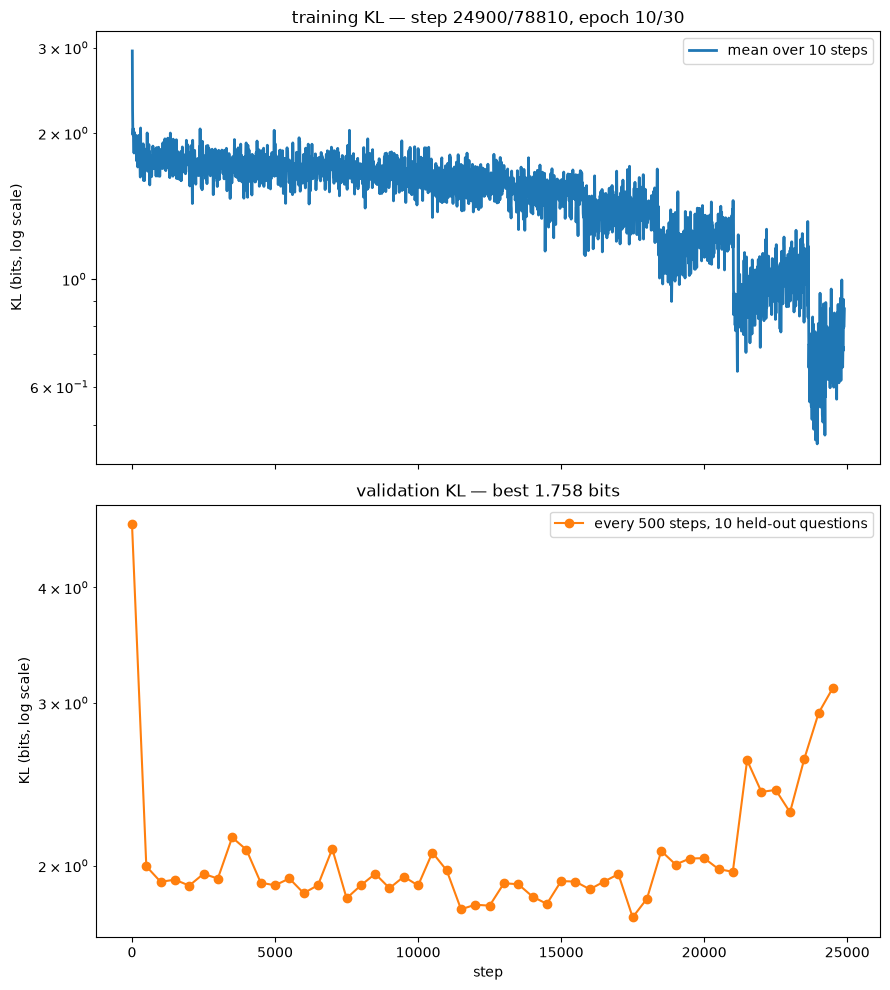

validation:   0%|          | 0/150 [00:00<?, ?batch/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


step 0: validation KL 4.681 bits


training:   0%|          | 0/78810 [00:00<?, ?step/s]

epoch 1:   0%|          | 0/2627 [00:00<?, ?step/s]

...

validation:   0%|          | 0/150 [00:00<?, ?batch/s]

step 24000: validation KL 2.926 bits
saved runs/train_2022-v4/last (step 24000)


validation:   0%|          | 0/150 [00:00<?, ?batch/s]

step 24500: validation KL 3.115 bits
saved runs/train_2022-v4/last (step 24500)


KeyboardInterrupt: 

In [12]:
window_kls = []                                                        # KL (bits) of every target since the last update
history = {"step": [], "step_kl": [], "logged_step": [], "window_kl": [], "val_step": [], "val_kl": []}

def validate_and_save():
    """Validation KL of the model as it is now, recorded in history; then the checkpoint to save_dir/last, and also to
    save_dir/best when its validation KL is the lowest so far."""
    global best_val_kl
    val_kl, _ = validate()
    history["val_step"].append(step)
    history["val_kl"].append(val_kl)
    tqdm.write(f"step {step}: validation KL {val_kl:.3f} bits")
    save_checkpoint("last")
    if val_kl < best_val_kl:
        best_val_kl = val_kl
        save_checkpoint("best")

fig, (ax_train, ax_val) = plt.subplots(2, 1, figsize=(9, 10), sharex=True)
handle = display(fig, display_id=True)                                 # the figure, redrawn in place at every update
plt.close(fig)                                                         # keep Jupyter from showing it a second time

def redraw():
    ax_train.clear()
    ax_train.plot(history["logged_step"], history["window_kl"], color="tab:blue", linewidth=2,
                  label=f"mean over {log_every} steps")
    ax_train.set_ylabel("KL (bits, log scale)")
    ax_train.set_yscale("log")                                         # equal ratios look equal: late gains stay visible
    ax_train.set_title(f"training KL — step {step}/{total_steps}, epoch {e + 1}/{epochs}")
    ax_train.legend(loc="upper right")
    ax_val.clear()
    ax_val.plot(history["val_step"], history["val_kl"], color="tab:orange", marker="o",
                label=f"every {val_every} steps, {len(val_questions)} held-out questions")
    ax_val.set_xlabel("step")
    ax_val.set_ylabel("KL (bits, log scale)")
    ax_val.set_yscale("log")
    ax_val.set_title(f"validation KL — best {min(history['val_kl'][1:], default=math.nan):.3f} bits")
    ax_val.legend(loc="upper right")
    fig.tight_layout()
    handle.update(fig)

val_kl, _ = validate()                                                 # the model before this training run (not saved)
history["val_step"].append(step)
history["val_kl"].append(val_kl)
best_val_kl = val_kl
tqdm.write(f"step {step}: validation KL {val_kl:.3f} bits")

overall = tqdm(total=total_steps, desc="training", unit="step")
for e in range(epochs):
    slots = rng.sample(slot_ids, len(slot_ids))                        # a new random order every epoch
    bar = tqdm(range(0, len(slots), batch), desc=f"epoch {e + 1}", total=steps_per_epoch, unit="step", leave=False)
    for start in bar:
        records = [draw_fn(s, rng, k) for s in slots[start:start + batch]]
        inputs = [model.prepare(r) for r in records]                   # (encoded record, targets in option order)
        logits = model.forward([x for x, _ in inputs])
        losses, step_kls = [], []
        for (_, targets), record_logits in zip(inputs, logits):
            for z, q in zip(record_logits, targets):
                t, logp = q["target"].to(device), torch.log_softmax(z.float(), -1)
                losses.append(-(t * logp).sum())                       # soft cross-entropy, as in train.py
                step_kls.append(((t[t > 0] * (t[t > 0].log() - logp[t > 0])).sum() / math.log(2)).item())
        loss = torch.stack(losses).mean()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.trainable_parameters(), 1.0)   # as train.py (MAX_GRAD_NORM)
        optimizer.step()
        scheduler.step()                                               # one-cycle: warm up, then cosine down
        optimizer.zero_grad()
        step += 1
        overall.update(1)
        window_kls += step_kls
        history["step"].append(step)
        history["step_kl"].append(sum(step_kls) / len(step_kls))
        if step % log_every == 0:
            history["logged_step"].append(step)
            history["window_kl"].append(sum(window_kls) / len(window_kls))
            overall.set_postfix(KL=f"{history['window_kl'][-1]:.3f}", lr=f"{scheduler.get_last_lr()[0]:.1e}")
            window_kls = []
        if step % val_every == 0:
            validate_and_save()
        if step % log_every == 0 or step % val_every == 0:
            redraw()
if step % val_every:
    validate_and_save()                                                # the final weights, unless just done
redraw()
overall.close()

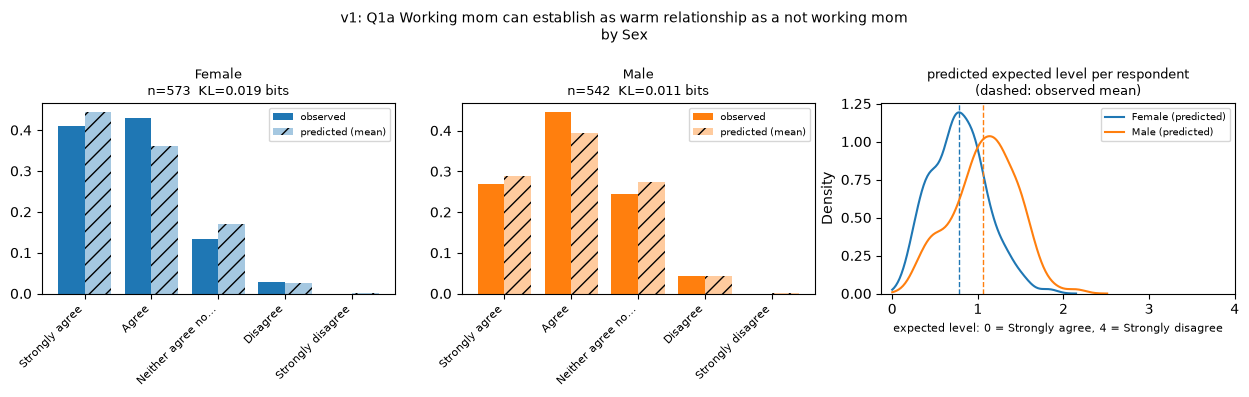

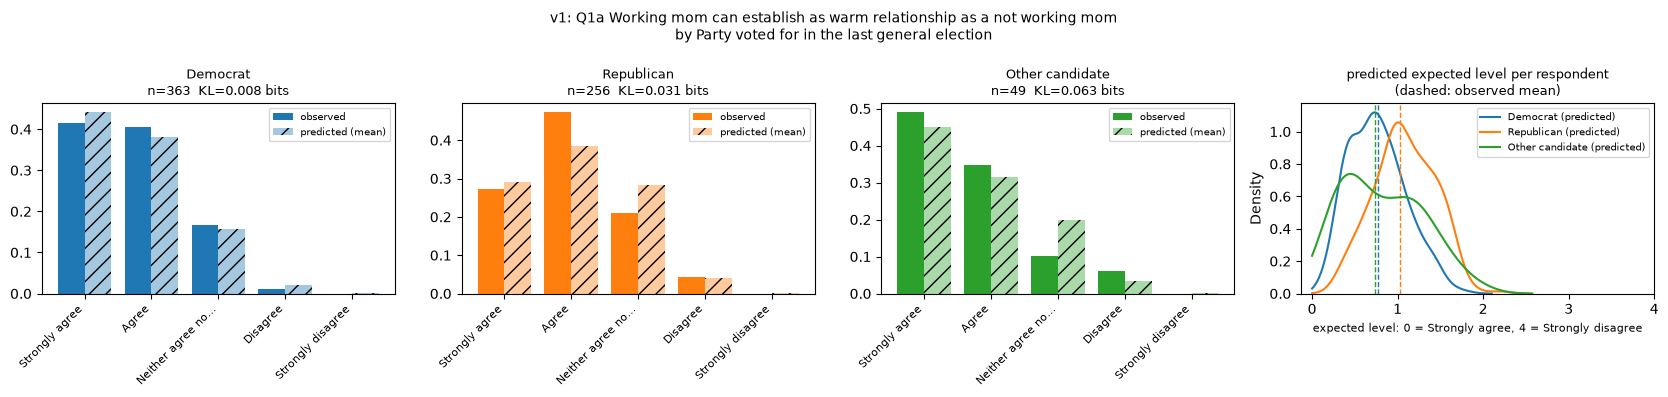

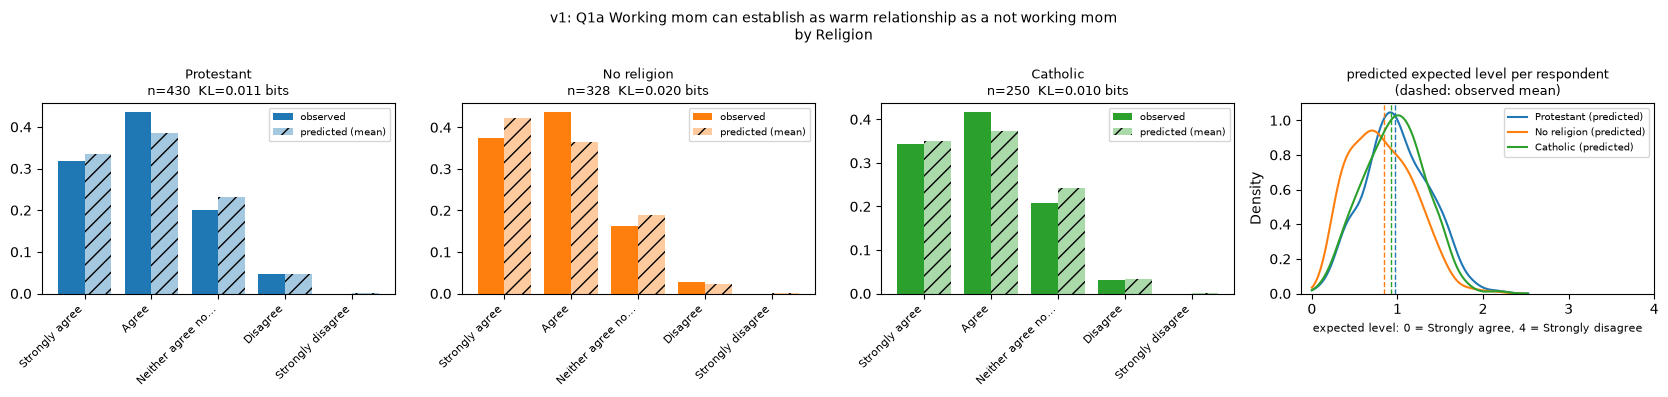

In [16]:
plot_learned("v1", "SEX")
plot_learned("v1", f"{country}_PRTY")
plot_learned("v1", "RELIGGRP")

In [14]:
checkpoint = save_dir / "best"                                         # the latest checkpoint; or another folder to load
del model
torch.cuda.empty_cache()                                               # free the current model before loading another

# to evaluate it (plots, predictions): the raw distribution, temperature 1
model = KevPointerModel.load(checkpoint, device)

# or, to keep training from it: its adapter and head, trainable
# model = KevPointerModel.build(str(checkpoint), device)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

# Custom prompt

In [17]:
v = "v1"
q = by_question[v].iloc[0]
print(repr(v) + ": " + repr({"question": q["question"], "options": list(q["option_texts"])}) + ",")

'v1': {'question': 'To begin, we have some questions about women. To what extent do you agree or disagree with the following statement? A working mother can establish just as warm and secure a relationship with her children as a mother who does not work.', 'options': ['Strongly agree', 'Agree', 'Neither agree nor disagree', 'Disagree', 'Strongly disagree']},


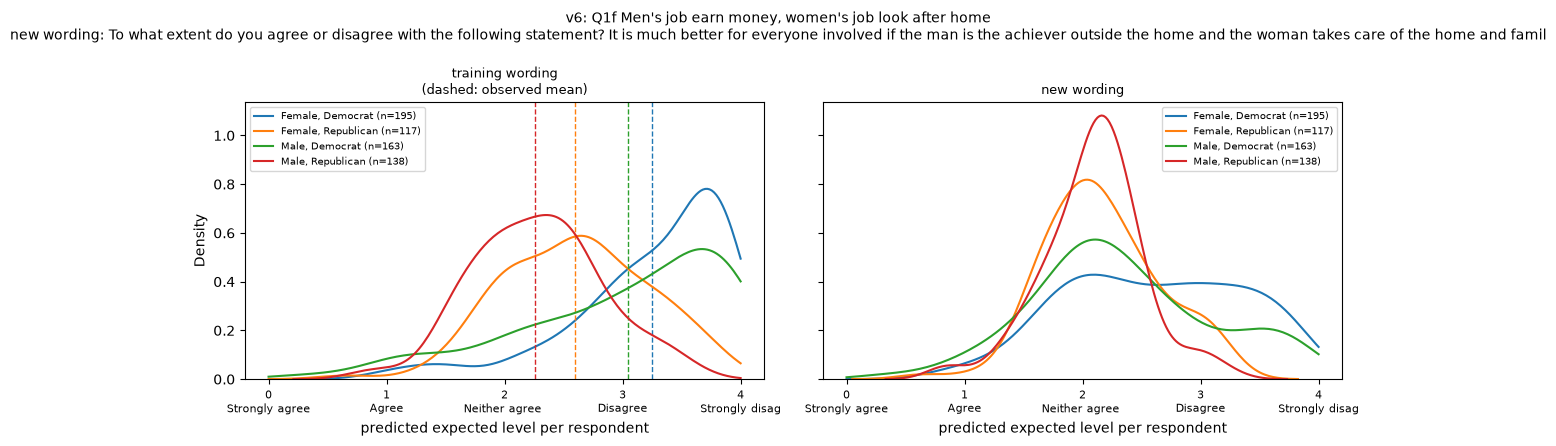

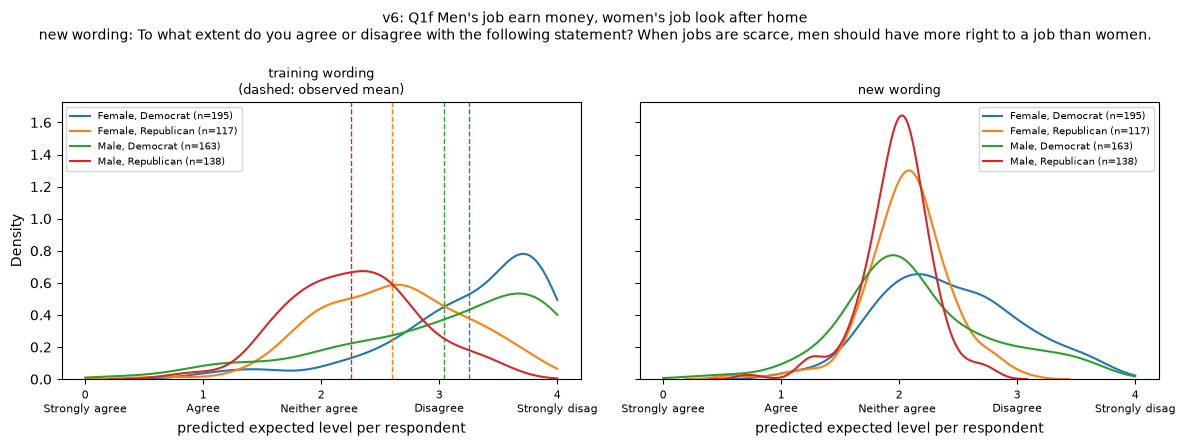

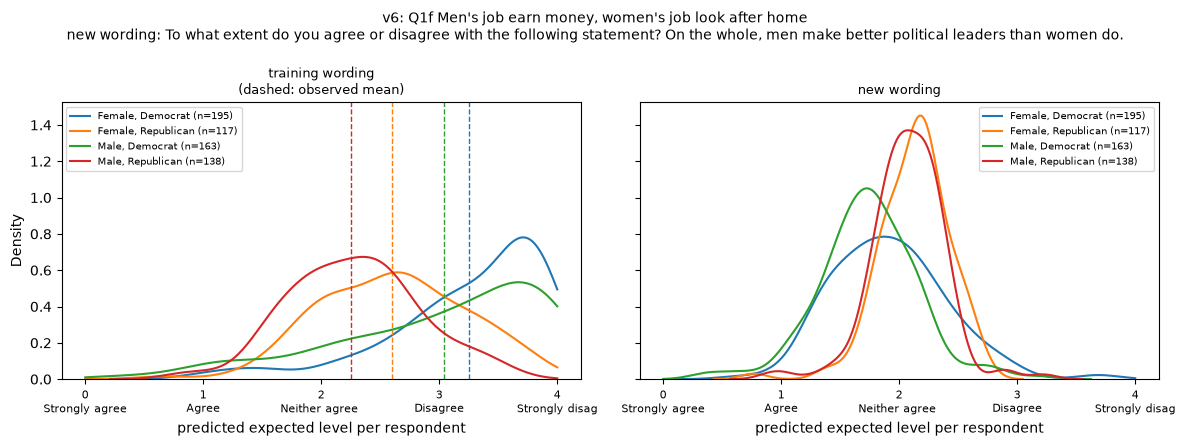

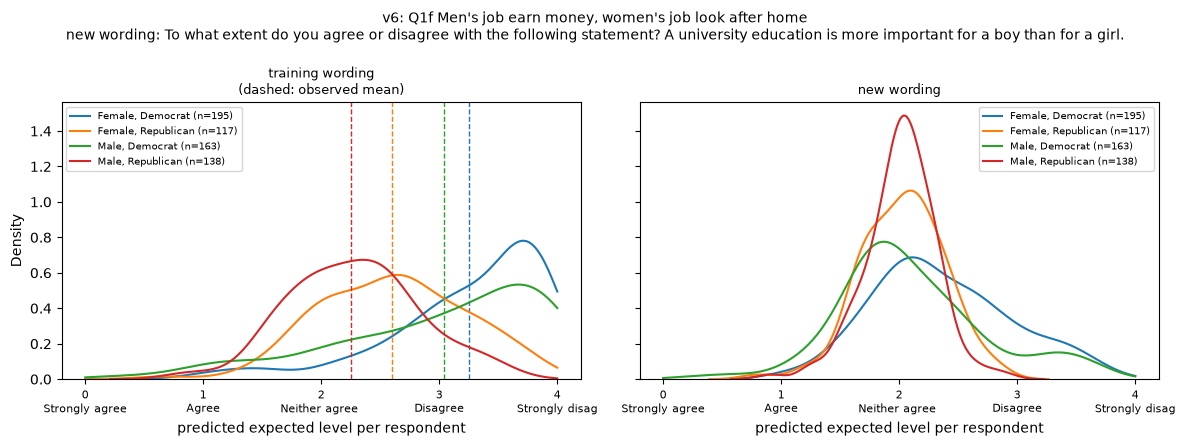

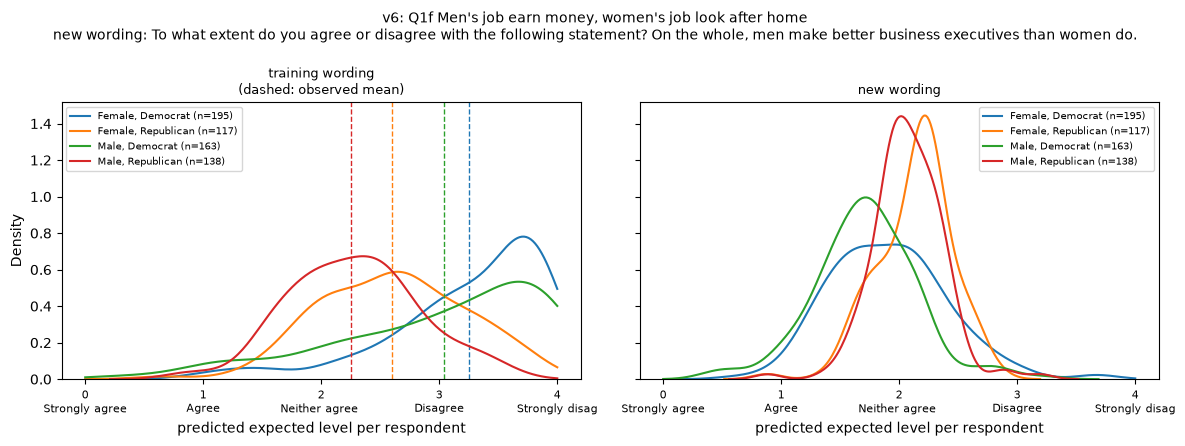

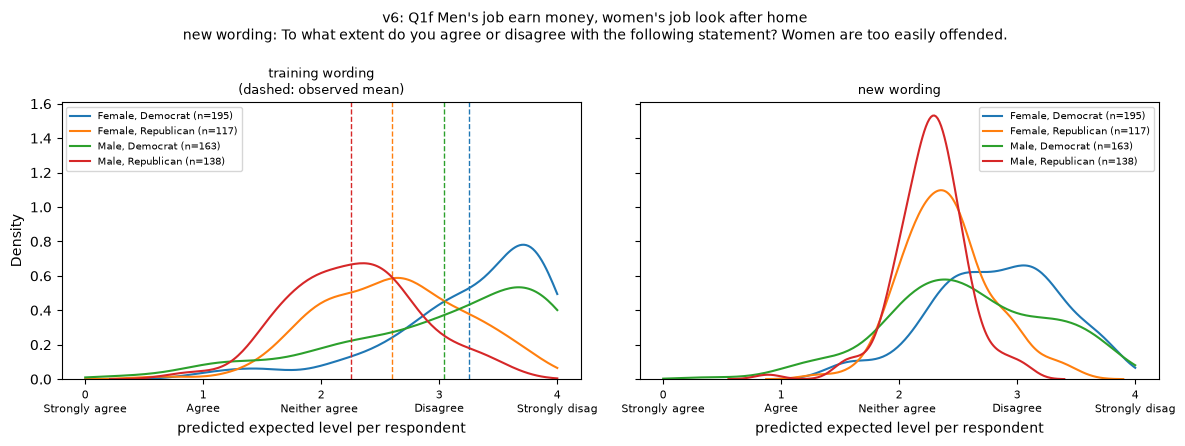

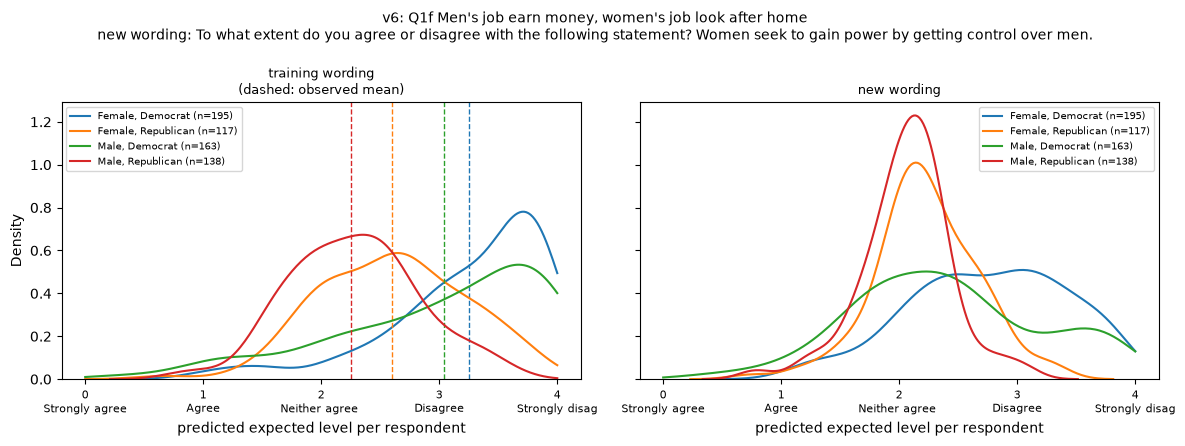

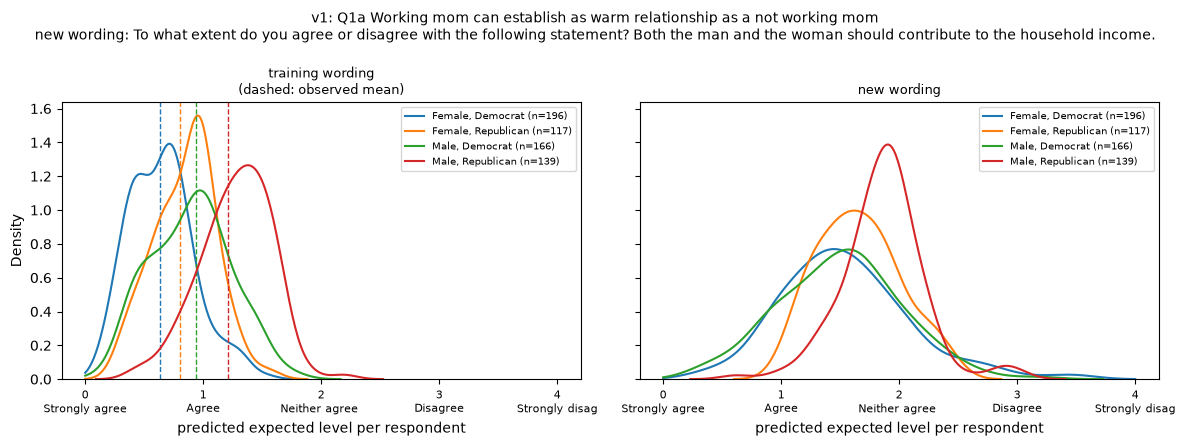

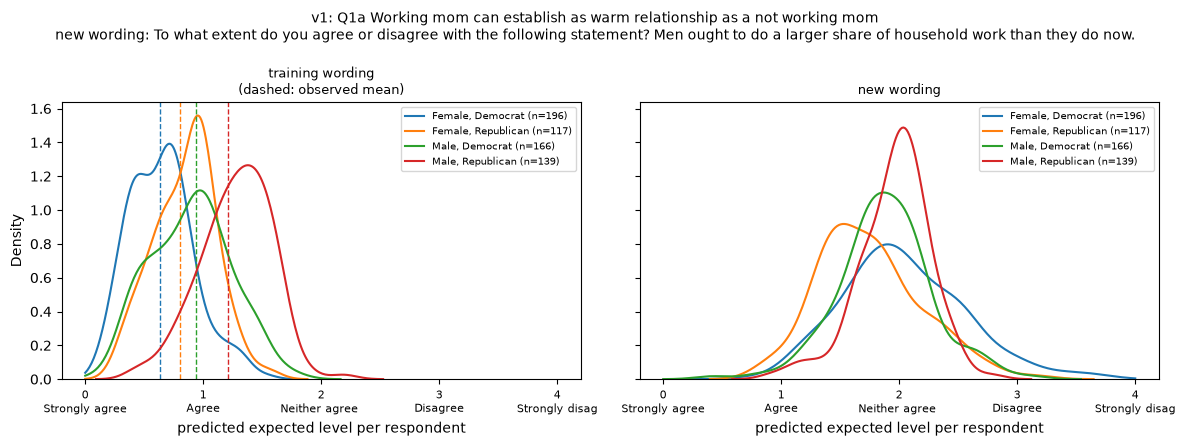

In [18]:
# ---- out-of-sample questions: each paired with the training question whose "agree" points the same way
# v6: agree = traditional roles; v1: agree = equal roles. Edit the strings in place.
wordings = [
    ("v6", {"question": "To what extent do you agree or disagree with the following statement? It is much better for "
                        "everyone involved if the man is the achiever outside the home and the woman takes care of "
                        "the home and family.",
            "options": ["Strongly agree", "Agree", "Neither agree nor disagree", "Disagree", "Strongly disagree"]}),
    ("v6", {"question": "To what extent do you agree or disagree with the following statement? When jobs are scarce, "
                        "men should have more right to a job than women.",
            "options": ["Strongly agree", "Agree", "Neither agree nor disagree", "Disagree", "Strongly disagree"]}),
    ("v6", {"question": "To what extent do you agree or disagree with the following statement? On the whole, men "
                        "make better political leaders than women do.",
            "options": ["Strongly agree", "Agree", "Neither agree nor disagree", "Disagree", "Strongly disagree"]}),
    ("v6", {"question": "To what extent do you agree or disagree with the following statement? A university "
                        "education is more important for a boy than for a girl.",
            "options": ["Strongly agree", "Agree", "Neither agree nor disagree", "Disagree", "Strongly disagree"]}),
    ("v6", {"question": "To what extent do you agree or disagree with the following statement? On the whole, men "
                        "make better business executives than women do.",
            "options": ["Strongly agree", "Agree", "Neither agree nor disagree", "Disagree", "Strongly disagree"]}),
    ("v6", {"question": "To what extent do you agree or disagree with the following statement? Women are too easily "
                        "offended.",
            "options": ["Strongly agree", "Agree", "Neither agree nor disagree", "Disagree", "Strongly disagree"]}),
    ("v6", {"question": "To what extent do you agree or disagree with the following statement? Women seek to gain "
                        "power by getting control over men.",
            "options": ["Strongly agree", "Agree", "Neither agree nor disagree", "Disagree", "Strongly disagree"]}),
    ("v1", {"question": "To what extent do you agree or disagree with the following statement? Both the man and the "
                        "woman should contribute to the household income.",
            "options": ["Strongly agree", "Agree", "Neither agree nor disagree", "Disagree", "Strongly disagree"]}),
    ("v1", {"question": "To what extent do you agree or disagree with the following statement? Men ought to do a "
                        "larger share of household work than they do now.",
            "options": ["Strongly agree", "Agree", "Neither agree nor disagree", "Disagree", "Strongly disagree"]}),
]

group_by = ["SEX", f"{country}_PRTY"]                                  # persona columns that define the groups

def reword(record, v, wording):
    """Record for question v with the question text, and option texts if given, replaced by `wording`."""
    q = record["questions"][v]
    q["instructions"] = wording["question"]
    if "options" in wording:
        if q["type"] == "score":
            q["criteria"] = list(wording["options"])                    # score targets are keyed by position
        else:
            q["criteria"] = {t: None for t in wording["options"]}
            q["target"] = dict(zip(wording["options"], q["target"].values()))
    return record

@torch.no_grad()
def predict_worded(rows, v, wording=None, eval_batch=64):
    """The model's distribution over question v's options for each row of long, its record drawn as in training
    (respondent record, current k, the row's own generator); with `wording`, the question reworded."""
    model.eval()
    out = []
    for start in range(0, len(rows), eval_batch):
        records = [draw_respondent(i, random.Random(int(i)), eval_k) for i in rows[start:start + eval_batch]]
        if wording is not None:
            records = [reword(r, v, wording) for r in records]
        inputs = [model.prepare(r) for r in records]
        logits = model.forward([x for x, _ in inputs])
        out += [torch.softmax(zs[0].float(), -1).cpu().numpy() for zs in logits]
    model.train()
    return np.stack(out)

def plot_wording_kde(v, wording, cols, min_n=30):
    """For score question v, the KDE of each respondent's predicted expected level, one curve per value combination of
    persona columns `cols` (held by at least min_n respondents): left with the training wording (dashed: the group's
    observed mean level), right with the new wording."""
    g = by_question[v].dropna(subset=cols)
    q = g.iloc[0]
    assert q["type"] == "score", f"{v} is a {q['type']} question: an expected level needs ordered options"
    sizes = g.groupby(cols).size()
    groups = [key if isinstance(key, tuple) else (key,) for key, n in sizes.items() if n >= min_n]
    codes = list(q["option_codes"])
    x = np.arange(len(codes))
    expected = {"training wording": predict_worded(list(g.index), v) @ x,         # each respondent's expected level
                "new wording": predict_worded(list(g.index), v, wording) @ x}
    level = np.array([codes.index(c) for c in g["answer_code"]])       # each respondent's observed option index
    colors = sns.color_palette("tab10", len(groups))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
    for ax, (label, e), texts in zip(axes, expected.items(), (list(q["option_texts"]), wording.get("options", list(q["option_texts"])))):
        for key, color in zip(groups, colors):
            rows = (g[cols] == pd.Series(dict(zip(cols, key)))).all(axis=1).to_numpy()
            sns.kdeplot(e[rows], ax=ax, color=color, label=f"{', '.join(map(str, key))} (n={rows.sum()})",
                        clip=(0, len(codes) - 1))
            if label == "training wording":
                ax.axvline(level[rows].mean(), color=color, linestyle="--", linewidth=1)
        ax.set_xticks(x, [f"{i}\n{t[:14]}" for i, t in zip(x, texts)], fontsize=8)
        ax.set_xlabel("predicted expected level per respondent")
        ax.set_title(label + ("\n(dashed: observed mean)" if label == "training wording" else ""), fontsize=9)
        ax.legend(fontsize=7)
    fig.suptitle(f"{v}: {q['label']}\nnew wording: {wording['question'][:200]}", fontsize=10)
    fig.tight_layout()
    plt.show()

for v, wording in wordings:
    plot_wording_kde(v, wording, group_by)

